In [ ]:
import pandas as pd
import numpy as np

# Load the datasets
results = pd.read_csv('results.csv')
races = pd.read_csv('races.csv')
drivers = pd.read_csv('drivers.csv')
constructors = pd.read_csv('constructors.csv')

# Merge them together
df = pd.merge(results, races[['raceId', 'year', 'circuitId', 'date']], on='raceId', how='left')
df = pd.merge(df, drivers[['driverId', 'driverRef']], on='driverId', how='left')
df = pd.merge(df, constructors[['constructorId', 'constructorRef']], on='constructorId', how='left')

print("Datasets merged successfully.")
print(df.head())

Datasets merged successfully.
   resultId  raceId  driverId  constructorId number  grid position  \
0         1      18         1              1     22     1        1   
1         2      18         2              2      3     5        2   
2         3      18         3              3      7     7        3   
3         4      18         4              4      5    11        4   
4         5      18         5              1     23     3        5   

  positionText  positionOrder  points  ...  fastestLap rank fastestLapTime  \
0            1              1    10.0  ...          39    2       1:27.452   
1            2              2     8.0  ...          41    3       1:27.739   
2            3              3     6.0  ...          41    5       1:28.090   
3            4              4     5.0  ...          58    7       1:28.603   
4            5              5     4.0  ...          43    1       1:27.418   

  fastestLapSpeed statusId  year circuitId        date   driverRef  \
0         

In [7]:
df.info

<bound method DataFrame.info of              date  circuitId  grid  Podium  driver_encoded  \
20034  1950-05-13          9  21.0       0             166   
20044  1950-05-13          9  12.0       0             471   
20035  1950-05-13          9   3.0       0             248   
20043  1950-05-13          9  10.0       0             613   
20042  1950-05-13          9   7.0       0             516   
...           ...        ...   ...     ...             ...   
26740  2024-12-08         24   3.0       1             701   
26739  2024-12-08         24   1.0       1             582   
26757  2024-12-08         24  20.0       0             170   
26747  2024-12-08         24   8.0       0              20   
26758  2024-12-08         24  10.0       0             609   

       constructor_encoded  
20034                   95  
20044                   65  
20035                    3  
20043                   65  
20042                   95  
...                    ...  
26740                   69  
26739                  131  
26757                  208  
26747                   11  
26758                  165  

[26759 rows x 6 columns]>

In [8]:
df.isnull().sum()

,0
date,0
circuitId,0
grid,0
Podium,0
driver_encoded,0
constructor_encoded,0


In [ ]:
# 1. Create Target Variable (1 for Podium [Top 3], 0 for Non-Podium)
df['Podium'] = np.where(df['positionOrder'] <= 3, 1, 0)

# 2. Prevent Data Leakage: Keep only features known BEFORE the race
features_to_keep = ['date', 'circuitId', 'driverRef', 'constructorRef', 'grid', 'Podium']
df = df[features_to_keep]

# 3. Handle Missing/Anomalous Data
# Drivers starting from the pitlane have a grid of '0'. This confuses ML models.
# We replace 0 with the median grid position to clean the data.
df['grid'] = df['grid'].replace(0, np.nan)
df['grid'] = df['grid'].fillna(df['grid'].median())

print("Target variable 'Podium' created and features cleaned.")
print(f"Dataset shape: {df.shape}")
display(df.head())

Target variable 'Podium' created and features cleaned.
Dataset shape: (26759, 6)


,date,circuitId,driverRef,constructorRef,grid,Podium
0,2008-03-16,1,hamilton,mclaren,1.0,1
1,2008-03-16,1,heidfeld,bmw_sauber,5.0,1
2,2008-03-16,1,rosberg,williams,7.0,1
3,2008-03-16,1,alonso,renault,11.0,0
4,2008-03-16,1,kovalainen,mclaren,3.0,0


In [ ]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# 1. Categorical Encoding (Turning names into numbers)
le_driver = LabelEncoder()
le_team = LabelEncoder()

df['driver_encoded'] = le_driver.fit_transform(df['driverRef'])
df['constructor_encoded'] = le_team.fit_transform(df['constructorRef'])

# Drop the original text columns now that we have number codes
df = df.drop(['driverRef', 'constructorRef'], axis=1)

# 2. Chronological Splitting (Preventing Future Data Leakage)
# We sort by date so the model trains on old races and tests on new races
df = df.sort_values(by='date')

# Define our Features (X) and Target (y)
X = df[['circuitId', 'grid', 'driver_encoded', 'constructor_encoded']]
y = df['Podium']

# 80:20 Split Ratio
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# 3. Feature Scaling (Standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set size: {X_train.shape[0]} rows (80%)")
print(f"Testing set size: {X_test.shape[0]} rows (20%)")
print("Phase 1 Complete! Data is cleaned, split, and ready for machine learning.")

Training set size: 21407 rows (80%)
Testing set size: 5352 rows (20%)
Phase 1 Complete! Data is cleaned, split, and ready for machine learning.


Training models... This may take a minute.

--- Model Performance Comparison ---


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.887519,0.771341,0.324359,0.456679
2,Random Forest,0.875000,0.600000,0.426923,0.498876
1,SVM,0.871824,0.725962,0.193590,0.305668
3,AdaBoost,0.862855,0.600877,0.175641,0.271825


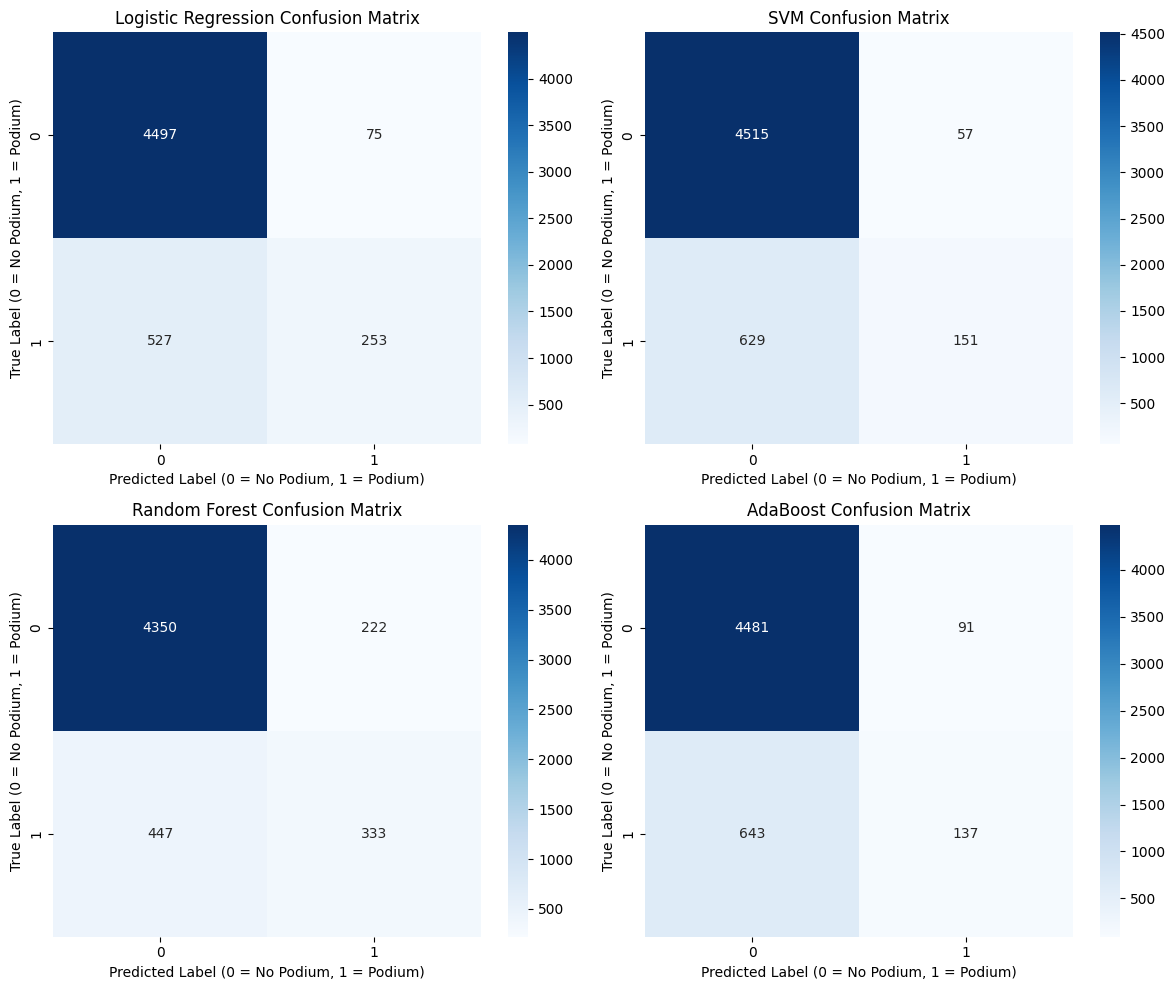

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import pandas as pd

# 1. Initialize the 4 Models
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "SVM": SVC(kernel='rbf', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=50, random_state=42)
}

# 2. Train, Predict, and Evaluate
results = []
confusion_matrices = {}

print("Training models... This may take a minute.")

for name, model in models.items():
    # Train the model
    model.fit(X_train_scaled, y_train)

    # Make predictions
    y_pred = model.predict(X_test_scaled)

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    # Store results
    results.append({"Model": name, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1-Score": f1})
    confusion_matrices[name] = confusion_matrix(y_test, y_pred)

# 3. Display the Performance Comparison Table
results_df = pd.DataFrame(results).sort_values(by="Accuracy", ascending=False)
print("\n--- Model Performance Comparison ---")
display(results_df)

# 4. Plot Confusion Matrices (For your Report Screenshots)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (name, cm) in enumerate(confusion_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx])
    axes[idx].set_title(f'{name} Confusion Matrix')
    axes[idx].set_xlabel('Predicted Label (0 = No Podium, 1 = Podium)')
    axes[idx].set_ylabel('True Label (0 = No Podium, 1 = Podium)')

plt.tight_layout()
plt.show()

In [ ]:
import joblib

# Assuming Random Forest was your best model.
# If it was Logistic Regression, change models["Random Forest"] to models["Logistic Regression"]
best_model = models["Random Forest"]

# Save the model and preprocessing tools
joblib.dump(best_model, 'f1_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(le_driver, 'le_driver.pkl')
joblib.dump(le_team, 'le_team.pkl')

print("Artifacts saved! Click the folder icon on the left sidebar to download these 4 .pkl files.")

Artifacts saved! Click the folder icon on the left sidebar to download these 4 .pkl files.


In [ ]:
import joblib

best_model = models["Random Forest"]

# Adding compress=3 will drastically shrink the file size!
joblib.dump(best_model, 'f1_model.pkl', compress=3)

print("Compressed model saved! Please download f1_model.pkl again.")

Compressed model saved! Please download f1_model.pkl again.
